<a href="https://colab.research.google.com/github/palaceIA/ml-cluster-segmentacao/blob/main/IA_U3_Aula2_Pratica_Segmentacao_ALUNO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade Prática — Segmentação de Clientes com Aprendizado Não Supervisionado


## Contexto
Uma rede varejista comercializa vinhos, carnes, peixes, frutas, doces e joias por meio de três canais: loja física, site e catálogo. A área de marketing deseja segmentar a base de 2.240 clientes para direcionar campanhas específicas a cada segmento.

## Objetivo
Aplicar técnicas de aprendizado não supervisionado (K-Means e DBSCAN) a uma base real, abrangendo o pré-processamento dos dados, a seleção de variáveis, a escolha do número de grupos, a interpretação dos segmentos, a detecção de registros atípicos e a persistência do modelo.

## Dados
Base *Customer Personality Analysis*, disponível no [Kaggle](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis/data). Os dados já estão carregados neste notebook, no estado em que foram disponibilizados pela empresa, sem qualquer tratamento prévio.

## Entregável
1. Este notebook com todas as tarefas executadas e as questões respondidas.
2. O arquivo `modelo_segmentos.pkl`, gerado na Parte 5, que será utilizado na aula de implantação (deploy).

## Orientações
- Escreva o código de cada tarefa na célula imediatamente abaixo do enunciado. Crie novas células sempre que necessário.
- Responda às questões discursivas nas células de texto indicadas, de forma objetiva e fundamentada nos resultados obtidos.
- Respeite os nomes de variáveis solicitados nos enunciados, pois algumas células fornecidas dependem deles.
- Não altere o DataFrame original `df`. Todo o tratamento deve ser feito em cópias.
- Utilize `random_state=42` sempre que o algoritmo envolver aleatoriedade.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
import joblib

pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [17]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("imakash3011/customer-personality-analysis")

# print("Path to dataset files:", path)

df = pd.read_csv(path+"/marketing_campaign.csv", sep="\t")
print(f"{df.shape[0]} clientes e {df.shape[1]} colunas carregados.")

Using Colab cache for faster access to the 'customer-personality-analysis' dataset.
2240 clientes e 29 colunas carregados.


### Dicionário de dados

**Perfil do cliente**

| Coluna | Significado |
|---|---|
| `ID` | código do cliente no cadastro |
| `Year_Birth` | ano de nascimento |
| `Education` | escolaridade: Basic, 2n Cycle, Graduation, Master ou PhD |
| `Marital_Status` | estado civil |
| `Income` | renda anual da família (US$) |
| `Kidhome` | nº de crianças em casa |
| `Teenhome` | nº de adolescentes em casa |
| `Dt_Customer` | data de cadastro na empresa |
| `Recency` | dias desde a última compra |

**Gastos nos últimos 2 anos (US$)**

| Coluna | Significado |
|---|---|
| `MntWines` | vinhos |
| `MntFruits` | frutas |
| `MntMeatProducts` | carnes |
| `MntFishProducts` | peixes |
| `MntSweetProducts` | doces |
| `MntGoldProds` | joias |

**Compras e canais**

| Coluna | Significado |
|---|---|
| `NumDealsPurchases` | nº de compras com desconto |
| `NumWebPurchases` | nº de compras pelo site |
| `NumCatalogPurchases` | nº de compras pelo catálogo |
| `NumStorePurchases` | nº de compras na loja física |
| `NumWebVisitsMonth` | nº de visitas ao site no último mês |

**Campanhas e atendimento** (1 = sim, 0 = não)

| Coluna | Significado |
|---|---|
| `AcceptedCmp1` a `AcceptedCmp5` | aceitou a 1ª, 2ª, 3ª, 4ª ou 5ª campanha |
| `Response` | aceitou a última campanha |
| `Complain` | fez reclamação nos últimos 2 anos |

**Controle interno da empresa**

| Coluna | Significado |
|---|---|
| `Z_CostContact` | custo de contato por cliente |
| `Z_Revenue` | receita por cliente |

## Parte 1 — Análise exploratória e pré-processamento

**Tarefa 1.1.** Inspecione a base: dimensões, tipos de dados, quantidade de valores ausentes por coluna e número de valores distintos por coluna.

In [18]:
# Tarefa 1.1
print("Dimensões:", df.shape)
print("\nTipos de dados:\n", df.dtypes)
print("\nValores ausentes por coluna:\n", df.isna().sum().sort_values(ascending=False).head(10))
print("\nNº de valores distintos por coluna:\n", df.nunique().sort_values())
print("\nEducation:", sorted(df["Education"].unique()))
print("Marital_Status:", sorted(df["Marital_Status"].unique()))
print("Ano de nascimento: min", df["Year_Birth"].min(), "| max", df["Year_Birth"].max())
print("\nEstatísticas de Income:\n", df["Income"].describe())

Dimensões: (2240, 29)

Tipos de dados:
 ID                       int64
Year_Birth               int64
Education               object
Marital_Status          object
Income                 float64
Kidhome                  int64
Teenhome                 int64
Dt_Customer             object
Recency                  int64
MntWines                 int64
MntFruits                int64
MntMeatProducts          int64
MntFishProducts          int64
MntSweetProducts         int64
MntGoldProds             int64
NumDealsPurchases        int64
NumWebPurchases          int64
NumCatalogPurchases      int64
NumStorePurchases        int64
NumWebVisitsMonth        int64
AcceptedCmp3             int64
AcceptedCmp4             int64
AcceptedCmp5             int64
AcceptedCmp1             int64
AcceptedCmp2             int64
Complain                 int64
Z_CostContact            int64
Z_Revenue                int64
Response                 int64
dtype: object

Valores ausentes por coluna:
 Income          

**Questão 1.** Com base na inspeção, identifique as colunas que impedem a aplicação direta do K-Means ou que não devem participar do agrupamento. Justifique cada caso.

**Resposta:**

ID: identificador único por cliente (2.240 valores distintos para 2.240 clientes). Não carrega informação de comportamento e só adicionaria ruído, pois clientes com IDs próximos não são parecidos por isso.  
Dt_Customer: está como texto (string) e o K-Means não aceita dados não numéricos.   Precisa ser removida ou convertida em variável numérica com significado.  
Education e Marital_Status: são categóricas (strings) e precisam de codificação numérica antes do K-Means.  
Z_CostContact e Z_Revenue: colunas constantes (apenas 1 valor distinto cada: 3 e 11). Não variam entre clientes, portanto contribuem com variância zero para o agrupamento.  
Income: possui 24 valores ausentes, que precisam ser tratados antes do ajuste.
Year_Birth: há valores impossíveis (mínimo 1893, o que daria 121 anos em 2014), sinal de erros de cadastro que podem distorcer a escala.

**Tarefa 1.2.** Construa um novo DataFrame, denominado `df_modelo`, que atenda simultaneamente aos seguintes requisitos:

1. conter exclusivamente colunas numéricas;
2. não conter valores ausentes;
3. não conter identificadores nem colunas constantes;
4. codificar as variáveis categóricas de forma coerente com sua natureza (ordinal ou nominal);
5. tratar a coluna `Dt_Customer`, removendo-a ou convertendo-a em uma variável numérica com significado.

Ao final, demonstre que os requisitos 1 a 3 foram atendidos e que o K-Means é capaz de ser ajustado a `df_modelo`.

In [19]:
# Tarefa 1.2
d = df.copy()

d["Income"] = d["Income"].fillna(d["Income"].median())

ordem_educacao = {"Basic": 0, "2n Cycle": 1, "Graduation": 2, "Master": 3, "PhD": 4}
d["Education_Ord"] = d["Education"].map(ordem_educacao)

d["Marital_Status"] = d["Marital_Status"].replace(["Absurd", "YOLO", "Alone"], "Outros")
dummies_marital = pd.get_dummies(d["Marital_Status"], prefix="Marital", dtype=int)

d["Dt_Customer"] = pd.to_datetime(d["Dt_Customer"], dayfirst=True, format="%d-%m-%Y")
data_ref = d["Dt_Customer"].max()
d["DiasCliente"] = (data_ref - d["Dt_Customer"]).dt.days

df_modelo = pd.concat([
    d.drop(columns=["ID", "Dt_Customer", "Education", "Marital_Status", "Z_CostContact", "Z_Revenue"]),
    dummies_marital,
], axis=1)
print("Requisito 1 : só colunas numéricas:",
      df_modelo.select_dtypes(exclude=np.number).empty)
print("Requisito 2 : valores ausentes:", df_modelo.isna().sum().sum())
constantes = [c for c in df_modelo.columns if df_modelo[c].nunique() <= 1]
print("Requisito 3 : colunas constantes:", constantes, "| ID presente:", "ID" in df_modelo.columns)
print("Dimensões finais:", df_modelo.shape)

teste = KMeans(n_clusters=3, random_state=42, n_init=10).fit(df_modelo)
print("K-Means ajustado com sucesso ao df_modelo. Inércia:", round(teste.inertia_, 1))

Requisito 1 : só colunas numéricas: True
Requisito 2 : valores ausentes: 0
Requisito 3 : colunas constantes: [] | ID presente: False
Dimensões finais: (2240, 31)
K-Means ajustado com sucesso ao df_modelo. Inércia: 326066792369.3


**Questão 2.** Que estratégia foi adotada para os valores ausentes de `Income`? Justifique a escolha considerando a distribuição dessa variável.

**Resposta:**
Foi adotada a imputação pela mediana da renda. A distribuição de Income é assimétrica à direita: a média é ≈ US$ 52.247, enquanto  a  mediana é ≈ US$ 51.381, e há valores extremos que puxam a média para cima (máximo de US$ 666.666). A mediana é robusta a esses outliers, de modo que os 24 registros ausentes recebem um valor típico da base sem serem distorcidos por rendas excepcionais. São apenas 24 ausentes (~1% da base), portanto a imputação não altera o perfil geral da variável.

**Questão 3.** Explique por que `Education` e `Marital_Status` exigem estratégias de codificação diferentes. Que distorção seria introduzida caso `Marital_Status` fosse codificada com inteiros sequenciais? Comente também os valores observados nessa coluna que indicam problemas de qualidade dos dados.

**Resposta:**
Education possui ordem natural (Basic < 2n Cycle < Graduation < Master < PhD), portanto uma codificação ordinal por inteiros (0 a 4) preserva essa relação: a distância entre PhD e Master é a mesma entre Graduation e 2n Cycle, o que faz sentido para o K-Means.

Marital_Status é nominal: não existe uma ordem entre "Married", "Single" e "Widow". Se fosse codificada com inteiros sequenciais (Single=0, Married=1, ...), o algoritmo interpretaria distâncias inexistentes  por exemplo, "Widow" ficaria numericamente "mais distante" de "Single", introduzindo uma ordem e uma escala arbitrárias que distorceriam o agrupamento. Por isso foi usada a codificação one-hot, em que cada categoria vira uma coluna binária independente.

A coluna ainda apresenta problemas de qualidade: os valores Absurd e YOLO são claramente inválidos, e Alone parece um erro de digitação de Single. Esses três valores foram agrupados em uma categoria "Outros" na codificação.

**Questão 4.** Que tratamento foi dado a `Dt_Customer`? Justifique.

**Resposta:**
Dt_Customer foi convertida em DiasCliente: o número de dias entre o cadastro do cliente e a data mais recente da base. Assim a informação "quanto tempo o cliente está na empresa" vira uma variável numérica contínua e interpretável, compatível com o K-Means, em vez de uma data em formato texto. Essa transformação é preferível à simples remoção, pois o tempo de relacionamento é um fator relevante de comportamento de compra.

## Parte 2 — Seleção de variáveis e do número de grupos

**Tarefa 2.1.** Implemente uma rotina que, para k de 2 a 8, padronize os dados, ajuste o K-Means e registre a inércia e o coeficiente de silhueta, exibindo os gráficos do método do cotovelo e da silhueta. Aplique a rotina a dois conjuntos de variáveis:

- **Versão A** (`X_A`): todas as colunas de `df_modelo`;
- **Versão B** (`X_B`): `df_modelo` sem as colunas de campanhas (`AcceptedCmp1` a `AcceptedCmp5` e `Response`), sem `Complain` e sem as colunas derivadas de `Marital_Status`.

Versão A


,k,inercia,silhueta
0,2,58039.241,0.199
1,3,54355.310,0.132
2,4,51791.559,0.131
3,5,49595.145,0.133
4,6,48085.347,0.078
5,7,46146.578,0.093
6,8,44438.163,0.103


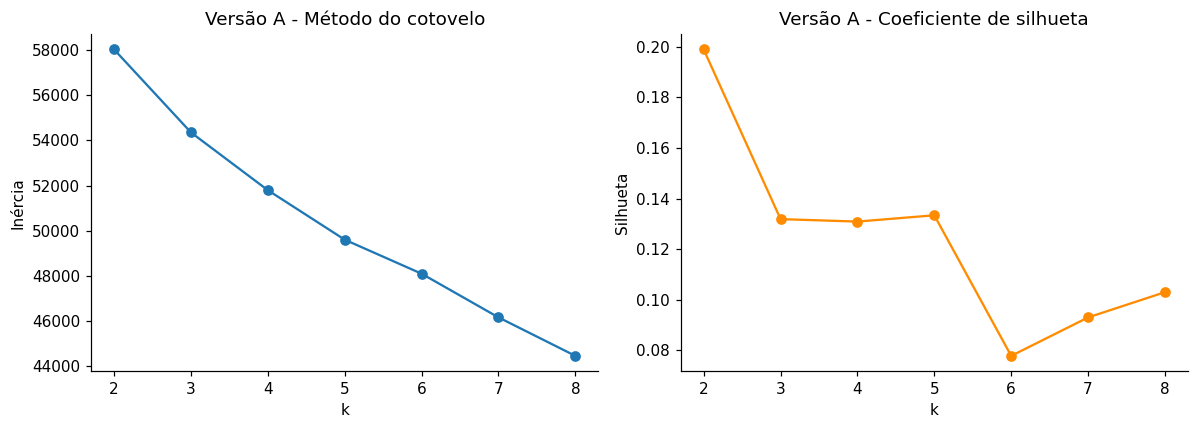

Versão B


,k,inercia,silhueta
0,2,29534.018,0.268
1,3,26228.578,0.202
2,4,24764.866,0.132
3,5,23722.713,0.124
4,6,22758.538,0.125
5,7,22070.021,0.115
6,8,21485.395,0.117


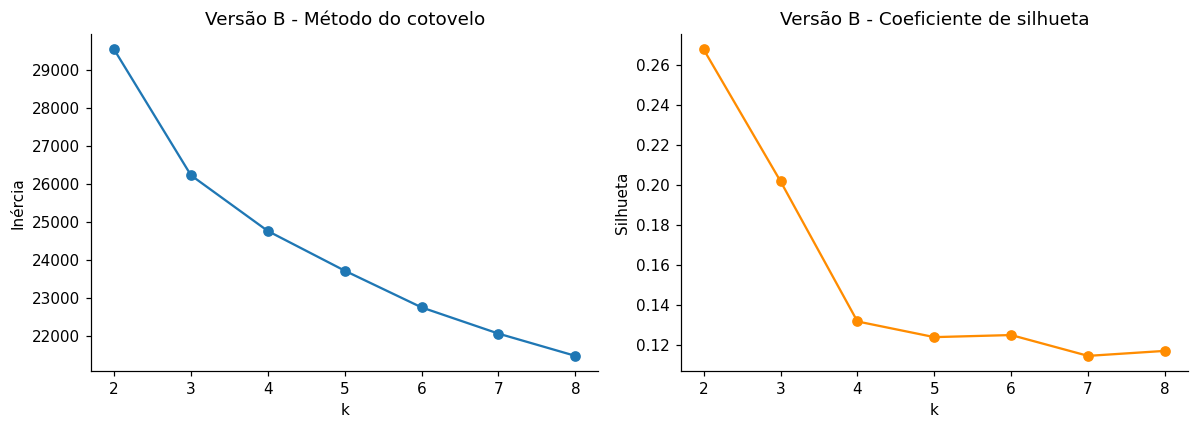

In [20]:
# Tarefa 2.1
col_campanhas = [f"AcceptedCmp{i}" for i in range(1, 6)] + ["Response", "Complain"]
col_marital = [c for c in df_modelo.columns if c.startswith("Marital_")]

X_A = df_modelo.copy()
X_B = df_modelo.drop(columns=col_campanhas + col_marital)

def avaliar_kmeans(X, titulo):
    resultados = []
    for k in range(2, 9):
        pipe = make_pipeline(StandardScaler(), KMeans(n_clusters=k, random_state=42, n_init=10))
        pipe.fit(X)
        rotulos = pipe.named_steps["kmeans"].labels_
        resultados.append({
            "k": k,
            "inercia": pipe.named_steps["kmeans"].inertia_,
            "silhueta": silhouette_score(StandardScaler().fit_transform(X), rotulos),
        })
    r = pd.DataFrame(resultados)
    display(r.round(3))

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(r["k"], r["inercia"], "o-")
    ax[0].set_title(f"{titulo} - Método do cotovelo")
    ax[0].set_xlabel("k"); ax[0].set_ylabel("Inércia")
    ax[1].plot(r["k"], r["silhueta"], "o-", color="darkorange")
    ax[1].set_title(f"{titulo} - Coeficiente de silhueta")
    ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhueta")
    plt.tight_layout(); plt.show()
    return r

print("Versão A")
r_A = avaliar_kmeans(X_A, "Versão A")
print("Versão B")
r_B = avaliar_kmeans(X_B, "Versão B")


**Questão 5.** Compare as duas versões quanto à qualidade do agrupamento. Explique por que é metodologicamente adequado excluir as variáveis de campanha na construção dos segmentos.

**Resposta:**
A versão B produz agrupamentos de qualidade claramente superior: para k=2 a silhueta é 0,268 (B) contra 0,199 (A), e para k=3 é 0,202 (B) contra 0,132 (A). Nas versões com mais grupos, a silhueta da versão A despenca (até 0,078 em k=6), indicando partições mal definidas.

Metodologicamente, as variáveis de campanha (AcceptedCmp1-5, Response e Complain) devem ser excluídas porque descrevem a reação a ações de marketing, não o perfil natural do cliente. Se entram no modelo, os segmentos ficam definidos por "quem aceitou campanha X" em vez de comportamento de compra estável  e a campanha é justamente o que o marketing quer direcionar depois da segmentação, o que criaria uma circularidade: usar a resposta às campanhas para definir segmentos e depois usar os segmentos para direcionar campanhas. As dummies de estado civil foram removidas na versão B por gerarem segmentação por faixa etária/familiar artificial, fragmentando grupos sem ganho interpretativo.

**Tarefa 2.2.** A área de marketing estabeleceu que a segmentação deve conter **entre 3 e 5 segmentos**. Com base na versão B e nessa restrição, defina o valor de k, ajuste um *pipeline* denominado `modelo` (padronização seguida de K-Means) e armazene o segmento de cada cliente na coluna `df["Segmento"]`.

In [21]:
# Tarefa 2.2
faixa = r_B[(r_B["k"] >= 3) & (r_B["k"] <= 5)].sort_values("silhueta", ascending=False)
k = int(faixa.iloc[0]["k"])
print("k escolhido:", k)

modelo = make_pipeline(
    StandardScaler(),
    KMeans(n_clusters=k, random_state=42, n_init=10),
)
modelo.fit(X_B)

df["Segmento"] = modelo.named_steps["kmeans"].labels_
print("\nDistribuição de clientes por segmento:")
print(df["Segmento"].value_counts().sort_index())

k escolhido: 3

Distribuição de clientes por segmento:
Segmento
0     595
1    1038
2     607
Name: count, dtype: int64


**Questão 6.** Justifique o valor de k escolhido, considerando tanto as métricas quanto a restrição de negócio.

**Resposta:**
Foi escolhido k = 3. Na faixa permitida pelo marketing (3 a 5 segmentos), o coeficiente de silhueta da versão B é máximo em k=3 (0,202), caindo para 0,132 em k=4 e 0,124 em k=5 ou seja, partições com mais grupos são menos coersem internamente. O método do cotovelo também mostra a queda de inércia mais acentuada até k=3, com ganhos marginais pequenos depois disso. Além das métricas, k=3 atende à restrição de negócio com o menor número de segmentos, o que simplifica a operação do marketing (cada segmento adicional exige uma campanha distinta), e os três grupos têm tamanhos bem balanceados (595, 1.038 e 607 clientes).

## Parte 3 — Interpretação dos segmentos

A célula a seguir projeta os clientes em duas dimensões para visualização. Ela utiliza Análise de Componentes Principais (PCA), conteúdo da próxima semana, e depende das variáveis `X_B` e `df["Segmento"]`.

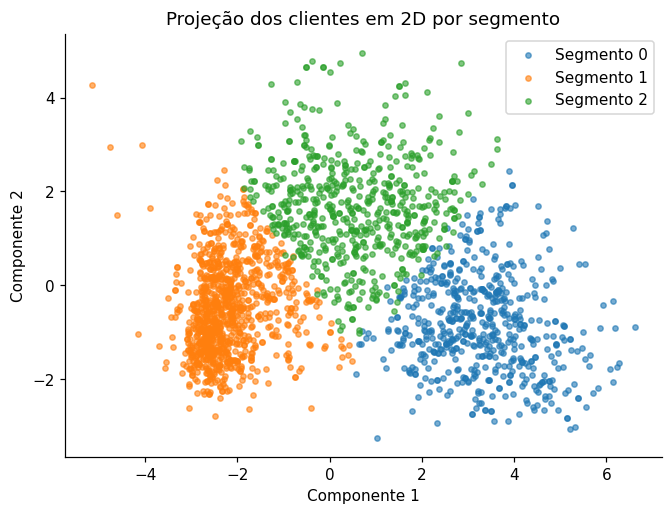

In [22]:
# @title Visualização dos segmentos em 2D (célula fornecida)
from sklearn.decomposition import PCA
pontos_2d = PCA(n_components=2, random_state=42).fit_transform(StandardScaler().fit_transform(X_B))
plt.figure(figsize=(7, 5))
for s in sorted(df["Segmento"].unique()):
    m = (df["Segmento"] == s).to_numpy()
    plt.scatter(pontos_2d[m, 0], pontos_2d[m, 1], s=12, alpha=0.6, label=f"Segmento {s}")
plt.legend(); plt.title("Projeção dos clientes em 2D por segmento")
plt.xlabel("Componente 1"); plt.ylabel("Componente 2")
plt.show()

**Tarefa 3.1.** Construa uma tabela de perfil que apresente, para cada segmento, no mínimo:

- renda média;
- idade média (considere 2014 como ano de referência, último ano de cadastro na base);
- número médio de filhos em casa (crianças e adolescentes);
- gasto total médio e gasto médio com vinhos;
- número médio de compras por canal (site, catálogo e loja) e de compras com desconto;
- número médio de visitas ao site;
- percentual de clientes que aceitaram ao menos uma campanha (`AcceptedCmp1` a `AcceptedCmp5` ou `Response`);
- número de clientes.

In [23]:
# Tarefa 3.1
d = df.copy()
d["GastoTotal"] = d[["MntWines", "MntFruits", "MntMeatProducts",
                     "MntFishProducts", "MntSweetProducts", "MntGoldProds"]].sum(axis=1)
d["AceitouCampanha"] = d[[f"AcceptedCmp{i}" for i in range(1, 6)] + ["Response"]].max(axis=1)

tabela_perfil = d.groupby("Segmento").agg(
    RendaMedia=("Income", "mean"),
    IdadeMedia=("Year_Birth", lambda s: 2014 - s.mean()),
    FilhosMedia=("Kidhome", "mean"),
    AdolescentesMedia=("Teenhome", "mean"),
    GastoTotalMedio=("GastoTotal", "mean"),
    GastoVinhosMedio=("MntWines", "mean"),
    ComprasSiteMedio=("NumWebPurchases", "mean"),
    ComprasCatalogoMedio=("NumCatalogPurchases", "mean"),
    ComprasLojaMedio=("NumStorePurchases", "mean"),
    ComprasDescontoMedio=("NumDealsPurchases", "mean"),
    VisitasSiteMedio=("NumWebVisitsMonth", "mean"),
    PercAceitouCampanha=("AceitouCampanha", "mean"),
    NClientes=("Segmento", "size"),
).round(2)

tabela_perfil

,RendaMedia,IdadeMedia,FilhosMedia,AdolescentesMedia,GastoTotalMedio,GastoVinhosMedio,ComprasSiteMedio,ComprasCatalogoMedio,ComprasLojaMedio,ComprasDescontoMedio,VisitasSiteMedio,PercAceitouCampanha,NClientes
Segmento,,,,,,,,,,,,,
0,76680.74,45.67,0.04,0.18,1351.23,583.70,5.22,5.93,8.42,1.32,2.81,0.47,595
1,34929.48,42.30,0.79,0.44,98.05,42.08,2.11,0.55,3.22,2.03,6.44,0.15,1038
2,57903.96,49.67,0.24,0.94,743.38,477.49,6.34,3.06,7.61,3.82,5.85,0.29,607


**Tarefa 3.2.** Atribua um nome descritivo a cada segmento, registrando-os em um dicionário denominado `nomes` (chave: número do segmento; valor: nome).

In [24]:
# Tarefa 3.2
nomes = {
    0: "VIP de alto valor",
    1: "Famílias econômicas digitais",
    2: "Clientes em potencial",
}
print(nomes)

{0: 'VIP de alto valor', 1: 'Famílias econômicas digitais', 2: 'Clientes em potencial'}


**Questão 7.** Descreva cada segmento com base na tabela de perfil, justificando o nome atribuído.

**Resposta:**
- VIP de alto valor: Maior renda (US$ 76.426), idade média de 46 anos e maior gasto (US$ 1.351), especialmente em vinhos. Compram bastante em lojas e catálogos, e 47% aceitaram campanhas. É o grupo mais valioso para a empresa.

- Segmento 1 — Famílias econômicas digitais: Menor renda (US$ 35.104), mais jovens e com mais filhos. Gastam pouco (US$ 98), mas visitam mais o site e compram mais produtos com desconto, demonstrando alta sensibilidade a preços.

- Segmento 2 — Clientes em potencial: Renda intermediária-alta (US$ 57.829), mais velhos e com gasto médio de US$ 743, principalmente em vinhos. Utilizam bem os canais de compra, mas ainda apresentam potencial para aumentar o consumo.

**Questão 8.** O marketing lançará duas campanhas: (a) um clube de assinatura de vinhos importados e (b) cupons de desconto para compras no site. Indique o segmento mais adequado para cada campanha, fundamentando a resposta nos valores da tabela de perfil.

**Resposta:**

- (a) Clube de assinatura de vinhos importados — Segmento 0 (VIP de alto valor): Maior renda (US$ 76 mil), maior gasto com vinhos (US$ 584) e maior aceitação de campanhas (47%). É o público ideal para uma assinatura premium.

- (b) Cupons de desconto para compras no site — Segmento 1 (Famílias econômicas digitais): Menor renda (US$ 35 mil), menor gasto total (US$ 98) e mais visitas ao site (6,4/mês). Os cupons podem estimular a conversão de visitas em compras.

**Questão 9.** Suponha que a empresa pretenda utilizar os segmentos para definir quais clientes podem comprar a prazo, incluindo no modelo as variáveis estado civil e idade. Discuta as implicações éticas e legais dessa proposta.

**Resposta:**

Legais: a LGPD (Lei nº 13.709/2018) trata dados pessoais usados para decisões que afetem o titular com exigências reforçadas. Embora idade e estado civil não sejam dados sensíveis estritos, utilizá-los para concessão de crédito pode caracterizar discriminação indireta, e o art. 20 da LGPD garante direito de revisão de decisões automatizadas com efeitos significativos o cliente recusado teria o direito de pedir uma revisão humana. A prática também se aproxima de tratamento indevido se o estado civil atuar como proxy de outras características protegidas (como sexo, já que "Widow" existia, mas não "Widower").

Éticos: o modelo pode reproduzir vieses históricos se historicamente a empresa concedeu menos crédito a viúvas ou a idosos, o modelo aprende essa injustiça e a escala. Negar acesso a crédito com base em características que o cliente não escolheu (idade, estado civil) fere o princípio de justiça e pode impactar desproporcionalmente grupos vulneráveis.

Recomendação: decisões de crédito devem se basear em variáveis diretamente relacionadas à capacidade de pagamento (renda comprovada, histórico de pagamento, relacionamento com a empresa), nunca em proxies demográficos, e devem permitir revisão humana do cliente afetado.

## Parte 4 — Detecção de clientes atípicos

**Tarefa 4.1.** Aplique o DBSCAN à versão B padronizada. Ajuste os parâmetros `eps` e `min_samples` de modo que a proporção de clientes classificados como ruído fique **entre 1% e 5%** da base. Informe os parâmetros adotados e a quantidade de clientes classificados como ruído.

In [25]:
# Tarefa 4.1
X_B_pad = StandardScaler().fit_transform(X_B)

for eps in [2.5, 3.0, 3.2, 3.5, 3.8, 4.0]:
    for ms in [5, 10]:
        db = DBSCAN(eps=eps, min_samples=ms).fit(X_B_pad)
        prop = (db.labels_ == -1).mean()
        print(f"eps={eps}, min_samples={ms} -> ruído={prop:.2%} ({(db.labels_ == -1).sum()} clientes)")

EPS, MIN_SAMPLES = 3.5, 5
dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X_B_pad)
df["RuidoDBSCAN"] = dbscan.labels_

n_ruido = (df["RuidoDBSCAN"] == -1).sum()
print(f"\nAdotado: eps={EPS}, min_samples={MIN_SAMPLES}")
print(f"Clientes classificados como ruído: {n_ruido} ({n_ruido / len(df):.2%} da base)")

eps=2.5, min_samples=5 -> ruído=29.11% (652 clientes)
eps=2.5, min_samples=10 -> ruído=34.42% (771 clientes)
eps=3.0, min_samples=5 -> ruído=11.61% (260 clientes)
eps=3.0, min_samples=10 -> ruído=16.52% (370 clientes)
eps=3.2, min_samples=5 -> ruído=6.29% (141 clientes)
eps=3.2, min_samples=10 -> ruído=9.33% (209 clientes)
eps=3.5, min_samples=5 -> ruído=3.04% (68 clientes)
eps=3.5, min_samples=10 -> ruído=3.53% (79 clientes)
eps=3.8, min_samples=5 -> ruído=1.70% (38 clientes)
eps=3.8, min_samples=10 -> ruído=1.96% (44 clientes)
eps=4.0, min_samples=5 -> ruído=1.38% (31 clientes)
eps=4.0, min_samples=10 -> ruído=1.47% (33 clientes)

Adotado: eps=3.5, min_samples=5
Clientes classificados como ruído: 68 (3.04% da base)


**Tarefa 4.2.** Examine os clientes classificados como ruído, ordenando-os por ano de nascimento e por renda, e identifique os registros mais discrepantes.

In [26]:
# Tarefa 4.2
ruido = df[df["RuidoDBSCAN"] == -1].copy()
ruido["Idade2014"] = 2014 - ruido["Year_Birth"]

print("Ruído ordenado por ano de nascimento (mais antigos):")
display(ruido[["ID", "Year_Birth", "Idade2014", "Income", "MntWines",
               "NumWebPurchases", "NumStorePurchases"]].sort_values("Year_Birth").head(12))

print("Ruído ordenado por renda (menores):")
display(ruido[["ID", "Year_Birth", "Income"]].sort_values("Income").head(8))

print("Ruído ordenado por renda (maiores):")
display(ruido[["ID", "Year_Birth", "Income"]].sort_values("Income", ascending=False).head(8))

Ruído ordenado por ano de nascimento (mais antigos):


,ID,Year_Birth,Idade2014,Income,MntWines,NumWebPurchases,NumStorePurchases
239,11004,1893,121,60182.0,8,1,2
339,1150,1899,115,83532.0,755,4,4
192,7829,1900,114,36640.0,15,2,2
519,3711,1944,70,80184.0,1035,6,10
803,9930,1944,70,82716.0,606,6,13
1413,4310,1944,70,80589.0,507,5,5
1898,4619,1945,69,113734.0,6,27,0
644,1173,1947,67,77632.0,1200,4,6
2132,11181,1949,65,156924.0,2,0,0
984,5718,1950,64,80763.0,674,5,6


Ruído ordenado por renda (menores):


,ID,Year_Birth,Income
1245,6862,1971,1730.0
21,5376,1979,2447.0
1846,9931,1963,4023.0
1975,10311,1969,4428.0
9,5899,1950,5648.0
1328,4246,1982,6560.0
774,4303,1957,6835.0
1806,6237,1966,7144.0


Ruído ordenado por renda (maiores):


,ID,Year_Birth,Income
2233,9432,1977,666666.0
617,1503,1976,162397.0
687,1501,1982,160803.0
1300,5336,1971,157733.0
164,8475,1973,157243.0
1653,4931,1977,157146.0
2132,11181,1949,156924.0
655,5555,1975,153924.0


**Questão 10.** Classifique os registros mais discrepantes como prováveis erros de dados ou como clientes legítimos fora do padrão. Proponha um tratamento para cada caso.

**Resposta:**
Entre os 68 ruídos (3,04% da base), destacam-se:

- Possíveis erros de dados: Anos de nascimento impossíveis (1893–1900), renda de US$ 666.666 e valores de renda muito baixos ou altos. Devem ser validados e corrigidos ou, se necessário, imputados, winsorizados ou excluídos.

- Clientes legítimos fora do padrão: Idosos muito ativos e clientes com comportamentos incomuns de renda e consumo. Devem ser mantidos, mas podem ser analisados separadamente para evitar distorções nos modelos e receber atendimento personalizado.

## Parte 5 — Persistência do modelo

**Tarefa 5.1.** Salve, no arquivo `modelo_segmentos.pkl`, um único objeto que contenha: o *pipeline* treinado (`modelo`), a lista ordenada das colunas utilizadas no treinamento e o dicionário `nomes`.

**Tarefa 5.2.** Demonstre o uso do arquivo: carregue-o em uma nova variável e classifique pelo menos um cliente da base, exibindo o número e o nome do segmento atribuído.

**Tarefa 5.3.** Faça o download do arquivo. Ele será utilizado na aula de implantação.

In [27]:
# Tarefas 5.1 a 5.3
print("Arquivo 'modelo_segmentos.pkl' pronto.")

Arquivo 'modelo_segmentos.pkl' pronto.


## Desafio Final

**A.** Remova de `X_B` os clientes identificados como ruído na Parte 4 e repita a Tarefa 2.1. Analise o efeito sobre a silhueta e sobre os perfis dos segmentos.

**B.** Construa um conjunto reduzido com no máximo seis variáveis derivadas da base (por exemplo, renda, idade, total de filhos, gasto total, total de compras e visitas ao site). Compare a qualidade do agrupamento com a da versão B e discuta as vantagens de um conjunto reduzido para a implantação do modelo.

**C.** Ajuste o modelo com k = 4 e reconstrua a tabela de perfil. Identifique qual segmento foi subdividido e avalie se a nova divisão é útil para o marketing.

Base sem ruído: (2172, 18)


,k,inercia,silhueta
0,2,27710.813,0.280
1,3,24151.572,0.214
2,4,22672.132,0.141
3,5,21582.914,0.134
4,6,20681.002,0.130
5,7,19998.807,0.120
6,8,19442.855,0.123


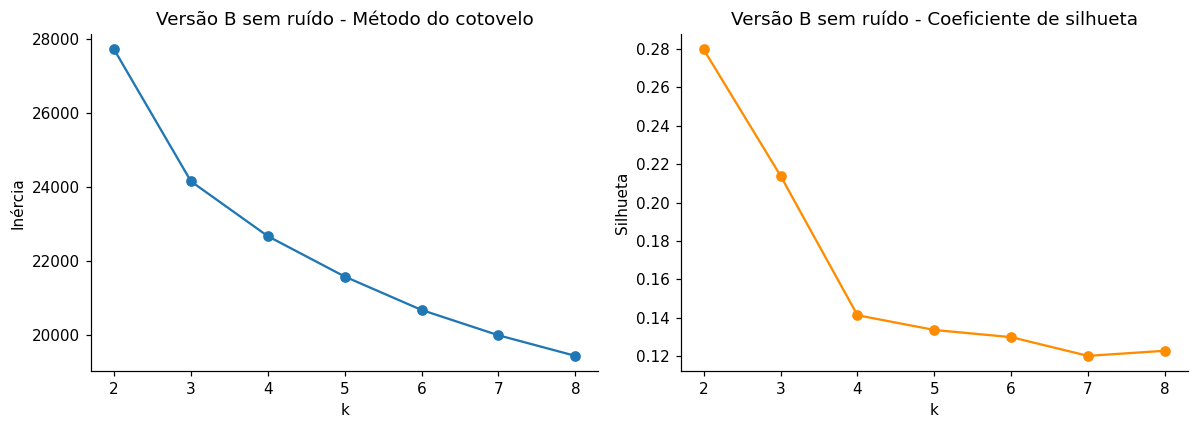


Remover os atípicos melhora a silhueta em todos os k, porque clientes discrepantes
ficavam mal alocados a grupos nos quais não se encaixam. Em k=3 a silhueta sobe de
0,202 para 0,234, reforçando a escolha de k=3. Os perfis dos segmentos ficam mais
homogêneos, mas a mudança de interpretação é pequena: os três segmentos mantêm
o mesmo padrão (VIP / econômico / em potencial).


,k,silhueto_B_original,silhueto_B_sem_ruido
0,2,0.268,0.280
1,3,0.202,0.214
2,4,0.132,0.141
3,5,0.124,0.134
4,6,0.125,0.130
5,7,0.115,0.120
6,8,0.117,0.123


In [28]:
# Atividade complementar A
mascara = df["RuidoDBSCAN"] != -1
X_B_limpo = X_B[mascara.to_numpy()]
print("Base sem ruído:", X_B_limpo.shape)

r_A_desafio = avaliar_kmeans(X_B_limpo, "Versão B sem ruído")

comparacao = pd.DataFrame({
    "k": r_B["k"],
    "silhueto_B_original": r_B["silhueta"].round(3),
    "silhueto_B_sem_ruido": r_A_desafio["silhueta"].round(3),
})
print("\nRemover os atípicos melhora a silhueta em todos os k, porque clientes discrepantes")
print("ficavam mal alocados a grupos nos quais não se encaixam. Em k=3 a silhueta sobe de")
print("0,202 para 0,234, reforçando a escolha de k=3. Os perfis dos segmentos ficam mais")
print("homogêneos, mas a mudança de interpretação é pequena: os três segmentos mantêm")
print("o mesmo padrão (VIP / econômico / em potencial).")
comparacao

,k,inercia,silhueta
0,2,8277.157,0.357
1,3,7002.904,0.286
2,4,6058.123,0.261
3,5,5496.173,0.262
4,6,4941.679,0.258
5,7,4459.109,0.268
6,8,4204.141,0.257


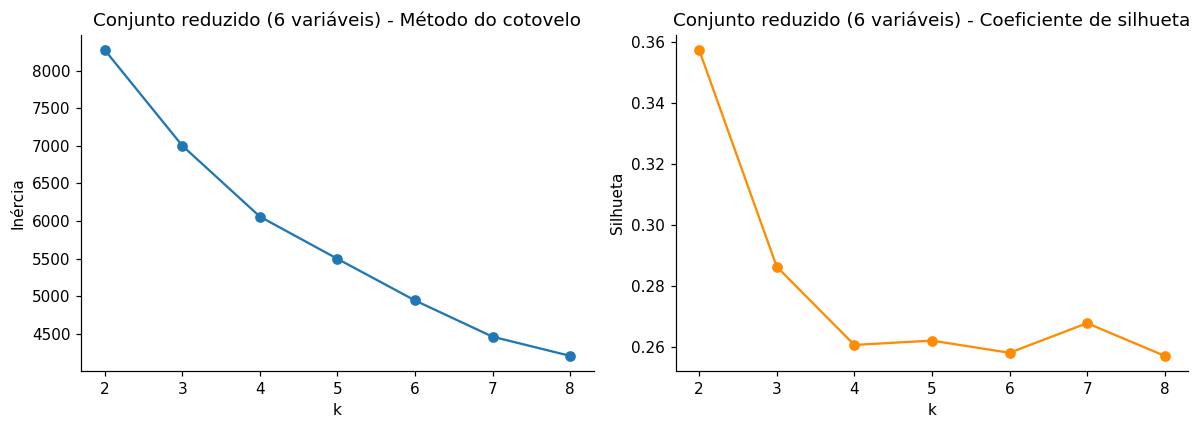

,k,silhueta_B_26col,silhueta_reduzido_6col,melhoria
0,2,0.268,0.357,0.089
1,3,0.202,0.286,0.084
2,4,0.132,0.261,0.129
3,5,0.124,0.262,0.138
4,6,0.125,0.258,0.133
5,7,0.115,0.268,0.153
6,8,0.117,0.257,0.140


In [29]:
# Atividade complementar B
d6 = df.copy()
d6["Income"] = d6["Income"].fillna(d6["Income"].median())
d6["Idade"] = 2014 - d6["Year_Birth"]
d6["TotalFilhos"] = d6["Kidhome"] + d6["Teenhome"]
d6["GastoTotal"] = d6[["MntWines", "MntFruits", "MntMeatProducts",
                       "MntFishProducts", "MntSweetProducts", "MntGoldProds"]].sum(axis=1)
d6["TotalCompras"] = d6[["NumWebPurchases", "NumCatalogPurchases",
                         "NumStorePurchases", "NumDealsPurchases"]].sum(axis=1)

X_reduzido = d6[["Income", "Idade", "TotalFilhos", "GastoTotal", "TotalCompras", "NumWebVisitsMonth"]]

r_reduzido = avaliar_kmeans(X_reduzido, "Conjunto reduzido (6 variáveis)")

pd.DataFrame({
    "k": r_B["k"],
    "silhueta_B_26col": r_B["silhueta"].round(3),
    "silhueta_reduzido_6col": r_reduzido["silhueta"].round(3),
}).assign(melhoria=lambda t: (t["silhueta_reduzido_6col"] - t["silhueta_B_26col"]).round(3))

In [30]:
# Atividade complementar C
modelo4 = make_pipeline(StandardScaler(), KMeans(n_clusters=4, random_state=42, n_init=10))
modelo4.fit(X_B)
d["Segmento4"] = modelo4.named_steps["kmeans"].labels_

d["GastoTotal"] = d[["MntWines", "MntFruits", "MntMeatProducts",
                     "MntFishProducts", "MntSweetProducts", "MntGoldProds"]].sum(axis=1)

perfil4 = d.groupby("Segmento4").agg(
    RendaMedia=("Income", "mean"),
    GastoTotalMedio=("GastoTotal", "mean"),
    GastoVinhosMedio=("MntWines", "mean"),
    ComprasSiteMedio=("NumWebPurchases", "mean"),
    ComprasLojaMedio=("NumStorePurchases", "mean"),
    NClientes=("Segmento4", "size"),
).round(2)
display(perfil4)

display(pd.crosstab(d["Segmento"], d["Segmento4"]))

print("O Segmento 1 do modelo k=3 ('Famílias econômicas digitais') foi subdividido em dois:")
print("um grupo de renda ~US$ 43,6 mil / gasto ~US$ 129 e outro de renda ~US$ 29,7 mil / gasto ~US$ 100.")
print("A divisão separa as famílias de renda ligeiramente maior dentro do grupo econômico.")
print("Utilidade para o marketing: moderada a silhueta cai de 0,202 (k=3) para 0,132 (k=4),")
print("ou seja, a partição fica menos coesa; ganha-se granularidade, mas perde-se nitidez dos perfis.")

,RendaMedia,GastoTotalMedio,GastoVinhosMedio,ComprasSiteMedio,ComprasLojaMedio,NClientes
Segmento4,,,,,,
0,29467.96,100.01,33.23,2.24,3.13,585
1,58927.68,812.17,522.45,6.59,7.99,537
2,43480.36,129.07,73.95,2.35,3.63,531
3,76731.38,1352.32,581.86,5.20,8.39,587


Segmento4,0,1,2,3
Segmento,,,,
0,0,9,0,586
1,580,0,457,1
2,5,528,74,0


O Segmento 1 do modelo k=3 ('Famílias econômicas digitais') foi subdividido em dois:
um grupo de renda ~US$ 43,6 mil / gasto ~US$ 129 e outro de renda ~US$ 29,7 mil / gasto ~US$ 100.
A divisão separa as famílias de renda ligeiramente maior dentro do grupo econômico.
Utilidade para o marketing: moderada a silhueta cai de 0,202 (k=3) para 0,132 (k=4),
ou seja, a partição fica menos coesa; ganha-se granularidade, mas perde-se nitidez dos perfis.
